# Figure S1 — Prior selections across datasets

Supplementary Information, pages 2-3: HBCA, scRNA DFU, Visium HD, Spatial DFU, MERFISH and scATAC.
Run each section independently after the setup cells. Use saved UMAP/spatial coordinates and original selection lists.
No model training, Lasso-View propagation or UMAP recomputation is performed. Input provenance is in `inputs/manifest.json`.

**Reproduction discrepancy:** The DFU text describes the intersection of the MMP1/MMP3 top-80% selections, but
`datasets_260407/see_wound.ipynb` actually used `|` (union) when saving the list. This notebook retains that saved selection.
The Spatial DFU color values use the original `score_genes` calculation, rather than raw MMP3 expression.

**Paths:** The first code cell discovers the data root and prints every input path. If needed, edit `DATA_ROOT` or individual entries in `DATA_FILES` there, then rerun from that cell. Bundled tables and outputs always use this supplementary folder. See `README.md` for details.


In [4]:
FIGURE = 'figS1'

from pathlib import Path

# Leave both settings as None to discover this folder and the data automatically.
# DATA_ROOT may be an absolute path or a path relative to this notebook folder.
SUPP_DIR = None  # Set only if the kernel starts outside the repository/workspace.
DATA_ROOT = None  # Explicit setting takes priority over LASSOARE_DATA_ROOT.

# Relative input paths use DATA_ROOT; individual absolute paths are also supported.
DATA_FILES = {
    'hbca': 'pub_epithelial_pca500.h5ad',
    'dfu': 'datasets_260407/adata_fib.h5ad',
    'visium': '10x_tmp/WT.h5ad',
    'spatial_dfu': 'datasets_260407/spatial_adata/merged_visium_spatial.h5ad',
    'merfish': 'merfish/merfish_downsampled.h5ad',
    'atac': 'atac_true/atac_processed.h5ad',
}

import os
import runpy

# An explicit folder or VS Code's notebook location takes priority over kernel cwd.
_folder = SUPP_DIR if SUPP_DIR is not None else os.environ.get('LASSOARE_SUPPLEMENTARY_DIR')
if _folder is not None:
    _candidates = [Path(_folder).expanduser().resolve()]
else:
    _anchors = []
    if globals().get('__vsc_ipynb_file__'):
        _anchors.append(Path(__vsc_ipynb_file__).expanduser().resolve().parent)
    _anchors.append(Path.cwd())
    _candidates = []
    for _anchor in _anchors:
        for _base in (_anchor, *_anchor.parents):
            _candidates.extend([
                _base, _base / 'supplementary', _base / 'figures_res/supplementary',
                _base / 'Lasso-ARE/figures_res/supplementary',
                _base / 'git_version/Lasso-ARE/figures_res/supplementary',
            ])
SUPP_DIR = next((_p.resolve() for _p in _candidates
                 if all((_p / _name).is_file() for _name in
                        ('supplementary_paths.py', 'supplementary_utils.py', 'inputs/manifest.json'))), None)
if SUPP_DIR is None:
    raise FileNotFoundError(
        f'Cannot locate the supplementary notebook folder from {Path.cwd()}. '
        'Set SUPP_DIR in this cell to the folder containing this notebook, '
        'supplementary_paths.py, supplementary_utils.py and inputs/.'
    )

# Load this copy directly, even if another supplementary folder was used by the kernel.
_paths = runpy.run_path(str(SUPP_DIR / 'supplementary_paths.py'))
_helpers = runpy.run_path(str(SUPP_DIR / 'supplementary_utils.py'))
for _name in ('require_file', 'read_metadata', 'read_expression', 'selection_mask',
              'set_selection', 'save_figure', 'plot_embedding'):
    globals()[_name] = _helpers[_name]
REPO_ROOT = _paths['repository_root'](SUPP_DIR)
DATA_ROOT, DATA_PATHS = _paths['resolve_data_paths'](SUPP_DIR, DATA_FILES, DATA_ROOT)
INPUT_DIR = SUPP_DIR / 'inputs'
OUTPUT_DIR = SUPP_DIR / 'output' / FIGURE
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams.update({'pdf.fonttype': 42, 'ps.fonttype': 42, 'font.family': 'DejaVu Sans'})
_paths['report_paths'](SUPP_DIR, DATA_ROOT, DATA_PATHS, OUTPUT_DIR)


Notebook folder: /home/zzj/lare/git_version/Lasso-ARE/figures_res/supplementary
Bundled inputs: /home/zzj/lare/git_version/Lasso-ARE/figures_res/supplementary/inputs
Data root: /home/zzj/lare
  OK hbca: /home/zzj/lare/pub_epithelial_pca500.h5ad
  OK dfu: /home/zzj/lare/datasets_260407/adata_fib.h5ad
  OK visium: /home/zzj/lare/10x_tmp/WT.h5ad
  OK spatial_dfu: /home/zzj/lare/datasets_260407/spatial_adata/merged_visium_spatial.h5ad
  OK merfish: /home/zzj/lare/merfish/merfish_downsampled.h5ad
  OK atac: /home/zzj/lare/atac_true/atac_processed.h5ad
Outputs: /home/zzj/lare/git_version/Lasso-ARE/figures_res/supplementary/output/figS1


In [5]:
import scanpy as sc
PATHS = {
    'hbca': DATA_PATHS['hbca'],
    'dfu': DATA_PATHS['dfu'],
    'visium': DATA_PATHS['visium'],
    'spatial_dfu': DATA_PATHS['spatial_dfu'],
    'merfish': DATA_PATHS['merfish'],
    'atac': DATA_PATHS['atac'],
}
SELECTION_DIR = INPUT_DIR / 'figS1'

def draw_selection(adata, mask, stem, title, basis='X_umap', size=1.0):
    set_selection(adata, mask)
    ax = plot_embedding(adata, 'selection', basis=basis, title=title, size=size)
    if basis == 'spatial':
        ax.invert_yaxis()
        ax.set_aspect('equal')
    save_figure(ax.figure, OUTPUT_DIR, stem)
    print(stem, ':', int(np.sum(mask)), '/', adata.n_obs, 'selected')

## S1a — HBCA: LHS3 and stripped nuclei

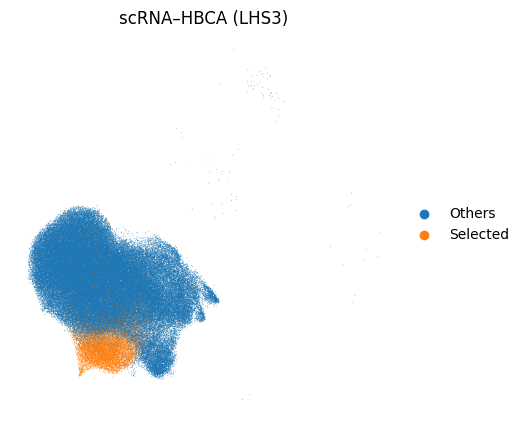

figS1a_lhs3 : 11373 / 130171 selected


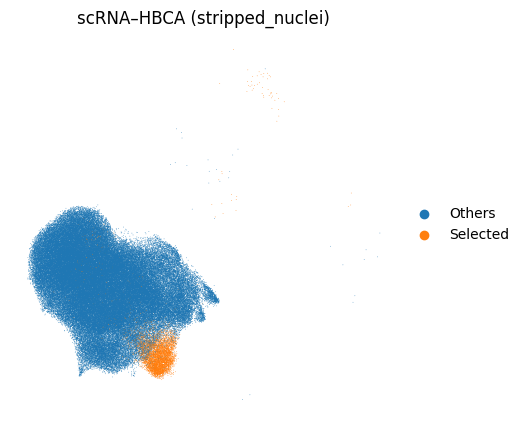

figS1a_stripped_nuclei : 5748 / 130171 selected


In [6]:
hbca = read_metadata(PATHS['hbca'])
for population, suffix in [('LHS3', 'lhs3'), ('stripped_nuclei', 'stripped_nuclei')]:
    mask = (hbca.obs['level2'].astype(str) == population).to_numpy()
    if population == 'stripped_nuclei':
        saved_mask = selection_mask(SELECTION_DIR / 'hbca_stripped_selected.txt', hbca.n_obs)
        if not np.array_equal(mask, saved_mask):
            raise ValueError('HBCA annotations and saved selection disagree; check source cell ordering.')
    draw_selection(hbca, mask, f'figS1a_{suffix}', f'scRNA–HBCA ({population})')
del hbca

## S1b — scRNA DFU: saved prior cells

/home/zzj/anaconda3/envs/env1/lib/python3.10/site-packages/anndata/_core/anndata.py:1756: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


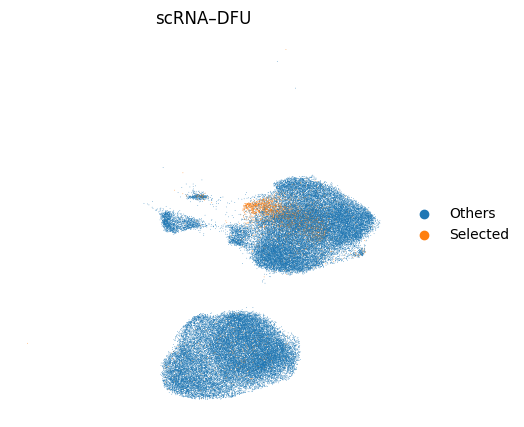

figS1b_dfu_selection : 3447 / 60727 selected


In [7]:
dfu = read_metadata(PATHS['dfu'])
mask = selection_mask(SELECTION_DIR / 'dfu_selected.txt', dfu.n_obs)
draw_selection(dfu, mask, 'figS1b_dfu_selection', 'scRNA–DFU')
del dfu

## S1c — Visium HD: TRAC selection

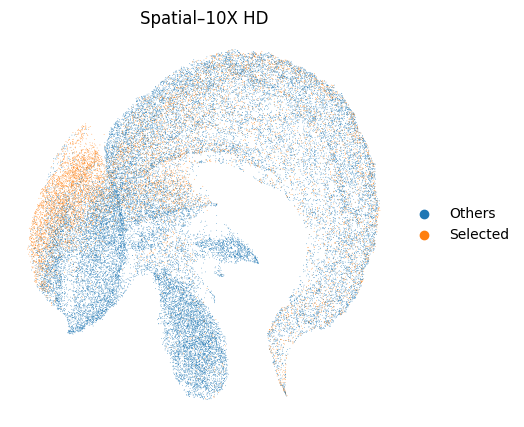

figS1c_visium_selection : 9249 / 38993 selected


In [8]:
visium = read_metadata(PATHS['visium'])
mask = selection_mask(SELECTION_DIR / 'visium_trac_selected.txt', visium.n_obs)
draw_selection(visium, mask, 'figS1c_visium_selection', 'Spatial–10X HD')
del visium

## S1d — Spatial DFU: UMAP, Wound1 and Wound7

Computing the original MMP3 gene score requires the full gene matrix and more memory than the other plotting sections.
`random_state=0` fixes control-gene sampling in score_genes, matching the default of the original call.
The first selection-list line contains the MMP3 selection. The second line belongs to a separate KRT6 experiment and is not merged.

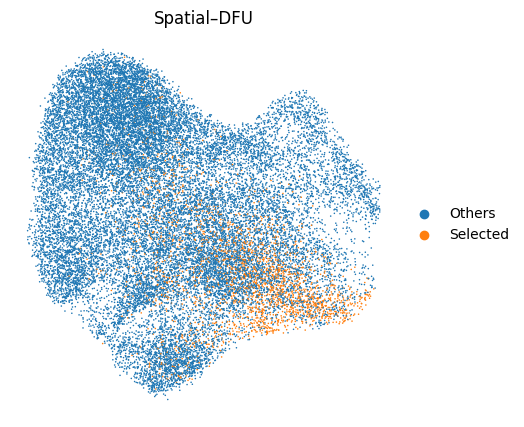

figS1d_spatial_dfu_umap : 2523 / 25913 selected


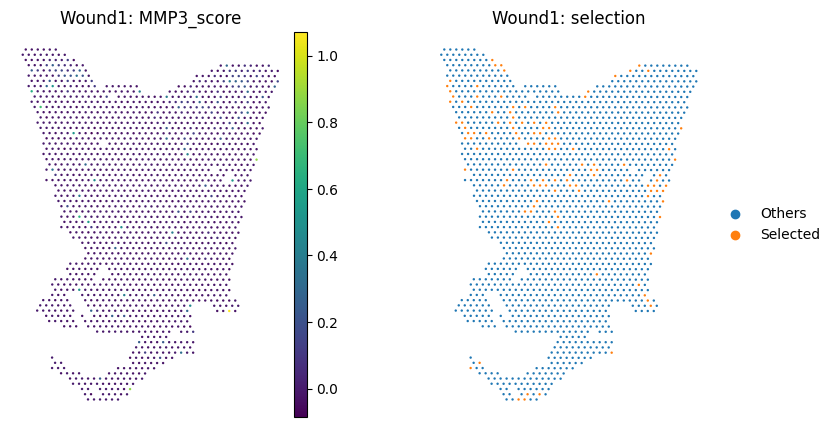

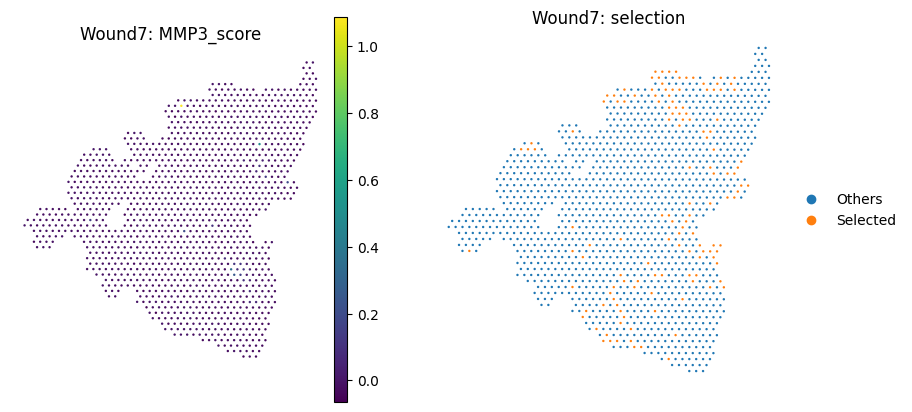

In [9]:
spatial = sc.read_h5ad(require_file(PATHS['spatial_dfu']))
mask = selection_mask(SELECTION_DIR / 'spatial_dfu_selected.txt', spatial.n_obs, line=0)
draw_selection(spatial, mask, 'figS1d_spatial_dfu_umap', 'Spatial–DFU', size=5)
sc.tl.score_genes(spatial, gene_list=['MMP3'], score_name='MMP3_score', random_state=0, use_raw=False)
for sample in ['Wound1', 'Wound7']:
    subset = spatial[spatial.obs['sample_id'].astype(str) == sample].copy()
    if subset.n_obs == 0:
        raise ValueError(f'No spots for {sample}')
    fig, axes = plt.subplots(1, 2, figsize=(10, 5))
    for ax, color in zip(axes, ['MMP3_score', 'selection']):
        plot_embedding(subset, color, basis='spatial', title=f'{sample}: {color}', size=12, ax=ax)
        ax.invert_yaxis()
        ax.set_aspect('equal')
    save_figure(fig, OUTPUT_DIR, f'figS1d_{sample}')
spatial.obs[['sample_id', 'MMP3_score', 'selection']].to_csv(OUTPUT_DIR / 'spatial_dfu_plot_values.csv')
del spatial, subset

## S1e — MERFISH: selected hippocampus region and major brain regions

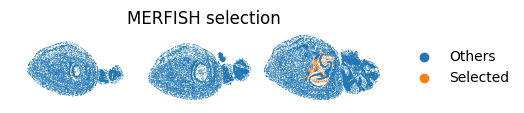

figS1e_merfish_selection : 788 / 40886 selected


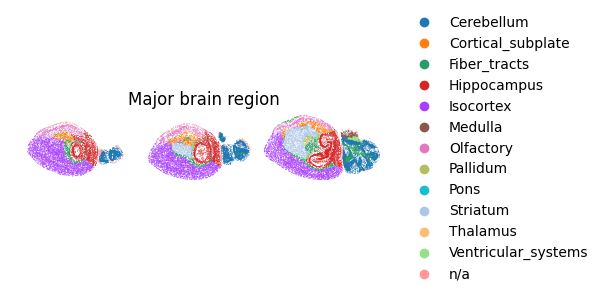

In [10]:
merfish = read_metadata(PATHS['merfish'], obsm_keys=['spatial'])
mask = selection_mask(SELECTION_DIR / 'merfish_selected.txt', merfish.n_obs)
draw_selection(merfish, mask, 'figS1e_merfish_selection', 'MERFISH selection', basis='spatial', size=1)
ax = plot_embedding(merfish, 'major_brain_region', basis='spatial', title='Major brain region', size=1)
ax.invert_yaxis()
ax.set_aspect('equal')
save_figure(ax.figure, OUTPUT_DIR, 'figS1e_merfish_regions')
del merfish

## S1f — scATAC: saved selection and cell types

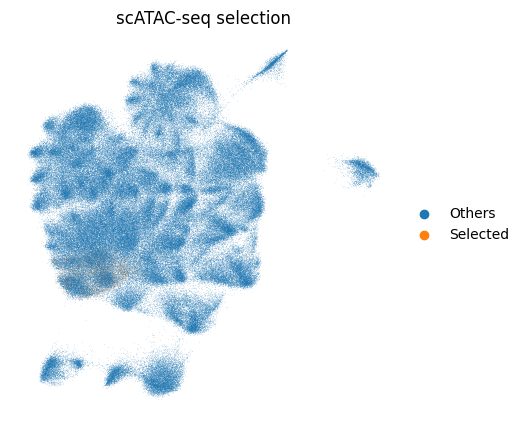

figS1f_atac_selection : 3088 / 259011 selected


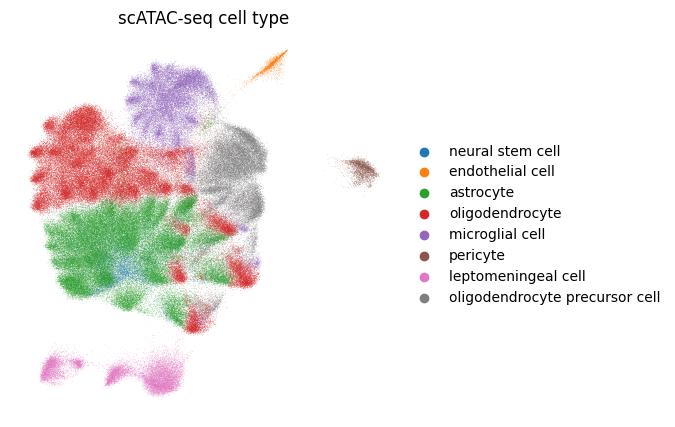

In [11]:
atac = read_metadata(PATHS['atac'])
mask = selection_mask(SELECTION_DIR / 'atac_selected.txt', atac.n_obs)
draw_selection(atac, mask, 'figS1f_atac_selection', 'scATAC-seq selection', size=0.4)
ax = plot_embedding(atac, 'cell_type', title='scATAC-seq cell type', size=0.4)
save_figure(ax.figure, OUTPUT_DIR, 'figS1f_atac_cell_types')
del atac